In [938]:
import functools
import numpy as np
import qiskit as qk
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qiskit_experiments as qk_e
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
import qutip as qt
from tqdm import tqdm

import sys
sys.path.append("../")
import pulse_simulator as ps

import matplotlib.pyplot as plt

# Activate IBM credentials

In [939]:
from qiskit_ibm_provider import IBMProvider

with open("../ibm_token.txt", "r") as file:
    IBM_TOKEN = file.read()
provider = IBMProvider(token=IBM_TOKEN, instance='ibm-q-ornl/ornl/phy147')

Get backend and backend configuration

In [940]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

# backend = qk_fp.FakeManila()
backend = provider.get_backend("ibm_nazca")
dt = backend.configuration().dt * ns

# desired_duration = 225 # dt
desired_duration = 120 # dt

# Can be acquired with backend.configuration().timing_constraints['granularity']
# granularity = 16
granularity = backend.configuration().timing_constraints['granularity']

GATE_TIME_SI_UNITS = desired_duration * dt / ns
# duration = ps.qiskit_closest_multiple_of_16(GATE_TIME_SI_UNITS, backend)
duration = ps.qiskit_closest_multiple(GATE_TIME_SI_UNITS, backend, granularity)
dt, granularity, duration

(0.5, 8, 120)

In [941]:
timing = qk_e.framework.BackendTiming(backend)
# timing.pulse_time(samples=len(pico_a[0]))
timing.pulse_time(time=GATE_TIME_SI_UNITS)

6.000000000000001e-08

In [942]:
backend.configuration().dt * ns

0.5

# Pairwise gate simulation
-----

## Custom pulses

### Load from PICO

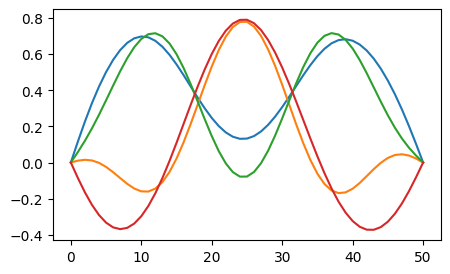

In [943]:
pico_a = ps.from_csv("../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv")
fig, ax = plt.subplots(figsize=[5,3])
for row in pico_a:
    ax.plot(row)

In [521]:
np.trapz(pico_a[0], dx=dt) / np.pi

3.3721320957550325

In [522]:
ps.get_amplitude_for_rotation(np.pi, row, dt)

1.7818694006536169

### Symbolic gates (interpolate with splines)

In [944]:
# TODO: This is a bit of a hack, but it works for now

def gateset_from_pico(duration, dt, pico_arr, keys, amp=1.0, angle=0.0):
    assert pico_arr.shape[0] == len(keys)

    gate_lookup = {}

    samples = pico_arr.shape[1]
    for k, row in zip(keys, pico_arr):
        signal_samples = ps.resample(
            duration, ps.get_samples(ps.custom_envelope(samples, row, dt=dt))
        )
        gate_lookup[k] = ps.scalable_symbolic_pulse(
            duration, signal_samples, "custom", amp=amp, angle=angle
        )

    return gate_lookup

In [945]:
pico_gates = {key: row for key, row in zip(["x1", "x2", "sx1", "sx2"], pico_a)}

In [946]:
# This will take some time at first
gates = gateset_from_pico(duration, dt, pico_a[:2], ["x1", "x2"]) 

In [947]:
# ... but now it's cached
y_gates = gateset_from_pico(duration, dt, pico_a[:2], ["x1", "x2"], amp=1, angle=np.pi / 2) 

In [948]:
np.trapz(ps.get_samples(gates["x1"]).real, dx=dt) / np.pi

3.3715481830837963

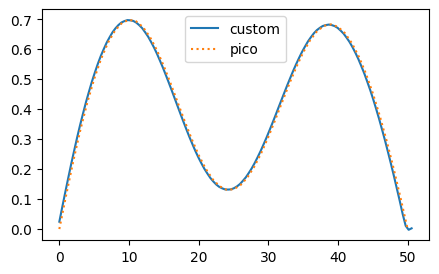

In [949]:
samples = ps.get_samples(gates["x1"])

fig, ax = plt.subplots(figsize=(5, 3))
# Rescale to match the original length
scale = pico_a.shape[1] / duration
plt.plot(np.arange(0, duration) * scale, samples.real / scale, label="custom")
plt.plot(np.arange(pico_a.shape[1]), pico_a[0], label="pico", ls=':')
plt.legend()

### Default gates (gaussians)

In [950]:
default_gates = {
    "x1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi/2),
    "x2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi/2),
    "sx1": ps.gaussian_envelope(duration, dt=dt, angle=np.pi/4),
    "sx2": ps.gaussian_envelope(duration, dt=dt, angle=np.pi/4),
}

# Test
np.trapz(ps.get_samples(default_gates["x1"]).real, dx=dt) / np.pi

0.49998637976724364

## Schedules

TODO: Can we change the samples in the waveform returned by SymbolicPulse?

We could rely on the previous (memoized) interpolation, but I am not sure exactly how to do it (or if it is necessary).

In [951]:
qubit_sched = {0: "x1", 1: "x2"}
# qubit_sched = {0: "x1"}

before = simpson(ps.get_samples(gates[qubit_sched[1]]).real, dx=dt)
print(f"Before {before / np.pi} π")

with qk.pulse.build(name="Robust moment", backend=backend) as robust_sched:
    for i, key in qubit_sched.items():
        channel = qk.pulse.DriveChannel(i)
        if i == 0:
            qk.pulse.shift_phase(np.pi/2, channel)
        qk.pulse.play(gates[key], channel)

with qk.pulse.build(name="Default moment", backend=backend) as default_sched:
    for i, key in qubit_sched.items():
        channel = qk.pulse.DriveChannel(i)
        if i == 0:
            qk.pulse.shift_phase(np.pi/2, channel)
        qk.pulse.play(default_gates[key], channel)

after = np.trapz(ps.get_samples(robust_sched.instructions[-1][1].pulse), dx=dt)
print(f"After (real) {after.real / np.pi} π")
print(f"After (imag) {after.imag / np.pi} π")

Before 1.1246243920814876 π
After (real) 1.1246262304094379 π
After (imag) 0.0 π


Two options: Circuit or pulse schedule.

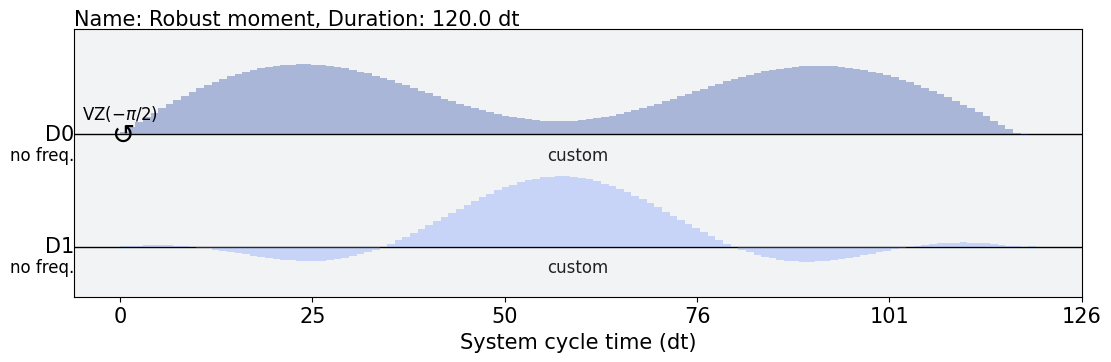

In [952]:
robust_sched.draw()

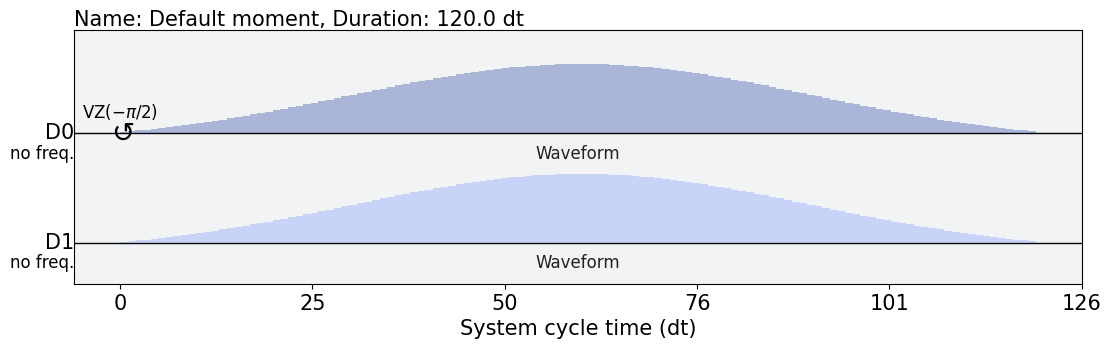

In [953]:
default_sched.draw()

## Models

In [954]:
# Define models fixed by the current parameters

# Backend
# =====
registers = [0, 1]

# NOTE: If the Rabi rates are True, you have to calibrate!
config_vars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Carrier frequencies of each control line
carriers = ps.backend_carriers(backend, config_vars)

# =====
H_rx = functools.partial(
    ps.rx_model, 
    registers=registers,
    backend=backend,
    variables=config_vars,
    rotating_frame=False,
)

A_decay = functools.partial(
    ps.qubit_decay_model,
    registers=registers, 
    variables=config_vars
)

H_xtalk = ps.crosstalk_model(
    registers,
    ps.backend_edges(backend),
    config_vars
)

# Create a system model
# =====
# Control model
#   Single qubit circuit moment: attach RX models to each qubit
H_drift = 0.
Hs_control = []
Hs_channels = []
As_static = []
for qubit, label in qubit_sched.items():
    
    # if qubit_index in registers:
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)

    # NOTE: doesn't work with quantum channel simulator yet
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    # Hs_control += Hjs_control
    # Double if RWA is used because 1/2 appears after rotating frame
    Hs_control += [2 * H for H in Hjs_control]
    Hs_channels += Hjs_channel
    As_static += Ajs_static

## Solvers

In [955]:
# Identity matrix
U0 = ps.qiskit_identity_operator(len(registers))

# # Identity channel
# C0 = qk.quantum_info.SuperOp(U0)

carriers = ps.backend_carriers(backend, config_vars)

In [956]:
xi_arr = np.linspace(0, 0.001, 10)
# target = ps.from_label("XX")
# target = ps.from_label("YY")
target = ps.from_label("YX")
H_xtalk_norm = H_xtalk / np.max(H_xtalk)

def solve_crosstalk(xi):
    _show_ops = False

    # Get the carriers
    registered_carriers = {c: carriers[c] for c in Hs_channels}
    rcf = 2 * np.mean(list(registered_carriers.values()))

    # Construct the solvers
    solver = qk_d.Solver(
        static_hamiltonian=H_drift.data + xi * np.zeros_like(H_xtalk_norm),
        hamiltonian_operators=Hs_control,
        hamiltonian_channels=Hs_channels,
        rotating_frame=H_drift,
        rwa_cutoff_freq=rcf,
        channel_carrier_freqs=registered_carriers,
        # channel_carrier_freqs={ch: 0. for ch in Hs_channels},
        dt=dt
    )

    solver_xtalk= qk_d.Solver(
        static_hamiltonian=H_drift.data + xi * H_xtalk_norm.data,
        hamiltonian_operators=Hs_control,
        hamiltonian_channels=Hs_channels,
        rotating_frame=H_drift,
        rwa_cutoff_freq=rcf,
        channel_carrier_freqs=registered_carriers,
        # channel_carrier_freqs={ch: 0. for ch in Hs_channels},
        dt=dt
    )

    # Rollout without crosstalk
    # -------------------------
    solver.model.evaluation_mode = 'sparse'
    sol = solver.solve(
        t_span=[0., duration * dt], 
        y0=U0, 
        signals=robust_sched,
        atol=1e-12,
        rtol=1e-12,
        method='jax_odeint'
    )
    sol_default = solver.solve(
        t_span=[0., duration * dt], 
        y0=U0, 
        signals=default_sched,
        atol=1e-12,
        rtol=1e-12,
        method='jax_odeint'
    )

    if _show_ops:
        without_crosstalk = sol.y[-1]
        without_crosstalk_default = sol_default.y[-1]
    else:
        without_crosstalk = qk.quantum_info.process_fidelity(sol.y[-1], target)
        without_crosstalk_default = qk.quantum_info.process_fidelity(sol_default.y[-1], target)

    # Rollout with crosstalk
    # ----------------------
    solver_xtalk.model.evaluation_mode = 'sparse'
    sol_xtalk = solver_xtalk.solve(
        t_span=[0., duration * dt], 
        t_eval=[duration * dt],
        y0=U0, 
        signals=robust_sched,
        atol=1e-16,
        rtol=1e-16,
        method='jax_odeint'
    )
    sol_xtalk_default = solver_xtalk.solve(
        t_span=[0., duration * dt], 
        t_eval=[duration * dt],
        y0=U0, 
        signals=default_sched,
        atol=1e-16,
        rtol=1e-16,
        method='jax_odeint'
    )

    if _show_ops:
        with_crosstalk = sol_xtalk.y[-1]
        with_crosstalk_default = sol_xtalk_default.y[-1]
    else:
        with_crosstalk = qk.quantum_info.process_fidelity(sol_xtalk.y[-1], target)
        with_crosstalk_default = qk.quantum_info.process_fidelity(sol_xtalk_default.y[-1], target)

    return xi, with_crosstalk, without_crosstalk, with_crosstalk_default, without_crosstalk_default

r = []
for xi in tqdm(xi_arr):
    r.append(solve_crosstalk(xi))
results = np.array(r).T

  0%|          | 0/10 [00:00<?, ?it/s]

100%|██████████| 10/10 [00:39<00:00,  3.94s/it]


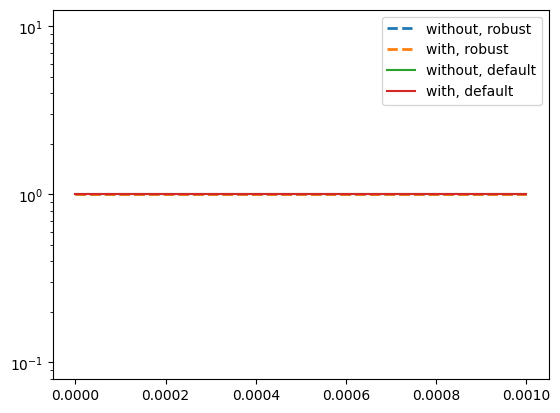

In [957]:
# Put a floor on the infidelity
infid_floor = np.max(1 - results[1:, 0])
infid = np.where(1 - results[1:] > infid_floor, 1 - results[1:], infid_floor)

fig, ax = plt.subplots()
# xi, with_crosstalk, without_crosstalk, with_crosstalk_default, without_crosstalk_default
ax.plot(results[0], infid[1], lw=2, ls='--', label='without, robust')
ax.plot(results[0], infid[0], lw=2, ls='--', label='with, robust')

ax.plot(results[0], infid[3], label='without, default')
ax.plot(results[0], infid[2], label='with, default')
ax.legend()
# ax.set_ylim([-0.1, 1.1])
ax.set_yscale('log')

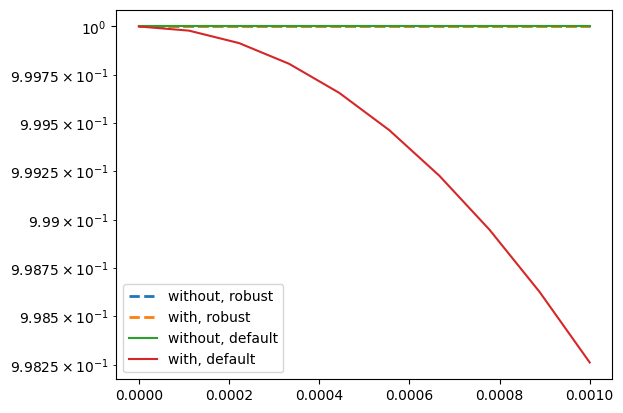

In [958]:
# Put a floor on the infidelity
infid = 1 - results[1:]

fig, ax = plt.subplots()
# xi, with_crosstalk, without_crosstalk, with_crosstalk_default, without_crosstalk_default
ax.plot(results[0], infid[1], lw=2, ls='--', label='without, robust')
ax.plot(results[0], infid[0], lw=2, ls='--', label='with, robust')

ax.plot(results[0], infid[3], label='without, default')
ax.plot(results[0], infid[2], label='with, default')
ax.legend()
# ax.set_ylim([-0.1, 1.1])
ax.set_yscale('log')

# Run calibration
-----

In [960]:
drive_amp = qk.circuit.Parameter('amp')
drive_amps = np.linspace(0.1, 1.2, 50)

In [961]:
pico_gates.keys()

dict_keys(['x1', 'x2', 'sx1', 'sx2'])

## Qiskit dynamics (simulated) calibration

In [974]:
# Rabi schedules as parameterized pulse instructions
# =====

# Create rabi schedule
qubit = 0
gate_key = "x1"
with qk.pulse.build(name="Rabi moment", backend=backend) as rabi_sched:
    signal = pico_gates[gate_key]
    signal_samples = ps.resample(
        duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
    )
    param_gate = ps.scalable_symbolic_pulse(
        duration, signal_samples, gate_key, amp=drive_amp
    )
    qk.pulse.play(param_gate, qk.pulse.DriveChannel(qubit))

# Assign parameters
exp_rabi_scheds = [rabi_sched.assign_parameters({drive_amp: a}, inplace=False) for a in drive_amps]

In [975]:
# Backend
# =====
registers = [0]

# NOTE: If the Rabi rates are True, you have to calibrate!
config_vars = ps.backend_simulation_vars(backend, rabi=True, units=Units)

# Carrier frequencies of each control line
carriers = ps.backend_carriers(backend, config_vars)

# =====
H_rx = functools.partial(
    ps.rx_model, 
    registers=registers,
    backend=backend,
    variables=config_vars,
    rotating_frame=True,
)

A_decay = functools.partial(
    ps.qubit_decay_model,
    registers=registers, 
    variables=config_vars
)

H_xtalk = ps.crosstalk_model(
    registers,
    ps.backend_edges(backend),
    config_vars
)

# Create a system model
# =====
# Control model
#   Single qubit circuit moment: attach RX models to each qubit
H_drift = 0.
Hs_control = []
Hs_channels = []
As_static = []
for qubit, label in qubit_sched.items():
    
    # if qubit_index in registers:
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)

    # NOTE: doesn't work with quantum channel simulator yet
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control
    Hs_channels += Hjs_channel
    As_static += Ajs_static

In [976]:
# Construct solver
solver = qk_d.Solver(
    static_hamiltonian=np.zeros_like(H_xtalk),
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    channel_carrier_freqs={ch: 0. for ch in Hs_channels},
    dt=dt
)

In [977]:
psi0 = ps.qiskit_ground_state(len(registers))

# Vmap of the rabi calibrations
solver.model.evaluation_mode = 'sparse'
solns = solver.solve(
    t_span=[0., duration * dt], 
    t_eval=[duration * dt],
    y0=psi0, 
    signals=exp_rabi_scheds,
    atol=1e-16,
    rtol=1e-16,
    method='jax_odeint'
)

rabi_data = np.array([np.abs(s.y[-1][1])**2 for s in solns])

To calibrate, let's just fit to a squared sine.

In [978]:
from scipy.optimize import curve_fit

In [979]:
def fit_function(x_values, y_values, function, init_params):
    fitparams, conv = curve_fit(function, x_values, y_values, init_params)
    y_fit = function(x_values, *fitparams)
    
    return fitparams, y_fit

In [980]:
# center data around 0
def baseline_remove(values):
    return np.array(values) - np.mean(values)

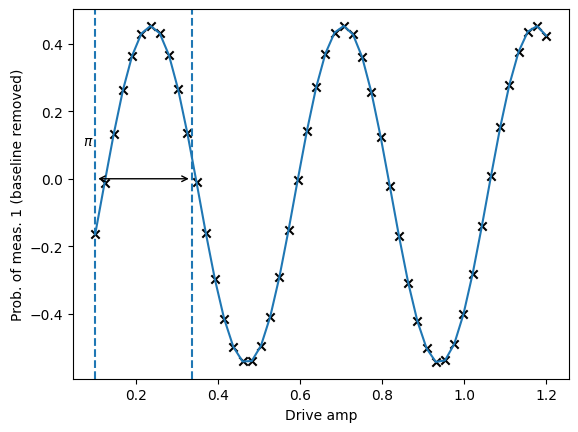

In [984]:
rabi_values = []

for i in rabi_data:
    rabi_values.append(i)

rabi_values = np.real(baseline_remove(rabi_values))

fit_params, y_fit = fit_function(drive_amps,
                                 rabi_values, 
                                 lambda x, A, B, drive_period, phi: (A*np.cos(2*np.pi*x/drive_period - phi) + B),
                                 [1, 1, 0.5, 0.5])

plt.scatter(drive_amps, rabi_values, marker='x', color='black')
plt.plot(drive_amps, y_fit)

drive_period = fit_params[2] # get period of rabi oscillation

plt.axvline(drive_amps[0] + drive_period/2, linestyle='--')
plt.axvline(drive_amps[0], linestyle='--')
plt.annotate("", xy=(drive_amps[0], 0), xytext=(drive_amps[0] + drive_period/2,0), arrowprops=dict(arrowstyle="<->"))
plt.annotate("$\pi$", xy=(drive_amps[0]-0.03, 0.1))

plt.xlabel("Drive amp")
plt.ylabel("Prob. of meas. 1 (baseline removed)")
plt.show()

In [988]:
drive_period / 2

0.23490327165742902

Check calibrated gate works

In [992]:
ideal_pulse = rabi_sched.assign_parameters({drive_amp: drive_period / 2}, inplace=False)
soln = solver.solve(
    t_span=[0., duration * dt], 
    t_eval=[duration * dt],
    y0=psi0, 
    signals=ideal_pulse,
    atol=1e-16,
    rtol=1e-16,
    method='jax_odeint'
)

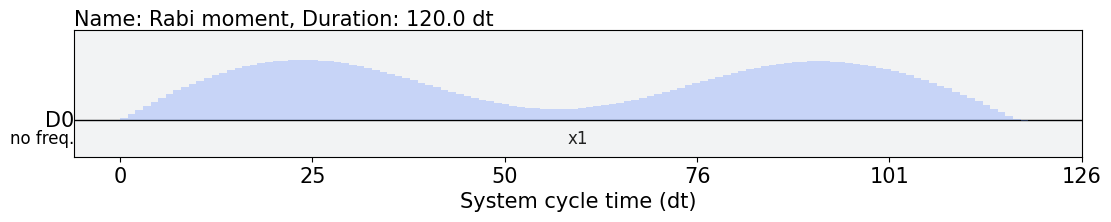

In [993]:
ideal_pulse.draw()

In [994]:
soln.y[-1]

Statevector([-2.2544858e-09+0.j,  0.0000000e+00-1.j],
            dims=(2,))


## Hardware calibration

In [1028]:
qubit = 0
gate_key = "sx2"
# freq = backend.defaults().qubit_freq_est[qubit]
# freq

In [1029]:
# with qk.pulse.build(name="Rabi moment", backend=backend) as rabi_sched:
#     signal = pico_gates[gate_key]

#     channel = qk.pulse.DriveChannel(qubit)
#     # qk.pulse.set_frequency(4 * GHz, channel)

#     signal_samples = ps.resample(
#         duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
#     )
#     param_gate = ps.scalable_symbolic_pulse(
#         duration, signal_samples, gate_key, amp=drive_amp
#     )
#     qk.pulse.play(param_gate, channel)

# # Assign parameters
# exp_rabi_scheds = [rabi_sched.assign_parameters({drive_amp: a}, inplace=False) for a in drive_amps]

In [1030]:
signal = pico_gates[gate_key]

channel = qk.pulse.DriveChannel(qubit)
# qk.pulse.set_frequency(4 * GHz, channel)
signal_samples = ps.resample(
    duration, ps.get_samples(ps.custom_envelope(len(signal), signal, dt=dt))
)

waveforms = []
for a in drive_amps:
    param_gate = ps.scalable_symbolic_pulse(
        duration, signal_samples, gate_key, amp=a
    ) 
    waveforms.append(param_gate.get_waveform())

In [1031]:
exp_rabi_scheds = []
for waveform in waveforms:
    with qk.pulse.build(name="Rabi moment", backend=backend) as rabi_sched:
        qk.pulse.play(waveform, channel)
    exp_rabi_scheds.append(rabi_sched)

In [1032]:
exp_rabi_circs = []
for rabi_sched in exp_rabi_scheds:
    rabi_gate = qk.circuit.Gate("rabi", 1, [])
    qc_rabi = qk.QuantumCircuit(1, 1)
    qc_rabi.append(rabi_gate, [0])
    qc_rabi.measure(0, 0)

    # Register a low-level, custom pulse definition for the given gate.
    qc_rabi.add_calibration(rabi_gate, (0,), rabi_sched)

    exp_rabi_circs.append(qc_rabi)

exp_rabi_circs[0].draw()

┌──────┐┌─┐
  q: ┤ rabi ├┤M├
     └──────┘└╥┘
c: 1/═════════╩═
              0

In [1033]:
# # Rabi circuits
# # =====

# # Add calibratable rabi gate to circuit
# rabi_gate = qk.circuit.Gate("rabi", 1, [drive_amp])
# qc_rabi = qk.QuantumCircuit(1, 1)
# qc_rabi.append(rabi_gate, [0])
# qc_rabi.measure(0, 0)

# # Register a low-level, custom pulse definition for the given gate.
# qc_rabi.add_calibration(rabi_gate, (0,), rabi_sched, [drive_amp])

# qc_rabi.draw()

In [1034]:
# Assign parameter value
# exp_rabi_circs = [qc_rabi.assign_parameters({drive_amp: a}, inplace=False) for a in drive_amps]

In [1035]:
# Check that the parameters have been assigned correctly
exp_rabi_circs[-1].get_instructions("rabi")

[CircuitInstruction(operation=Instruction(name='rabi', num_qubits=1, num_clbits=0, params=[]), qubits=(Qubit(QuantumRegister(1, 'q'), 0),), clbits=())]

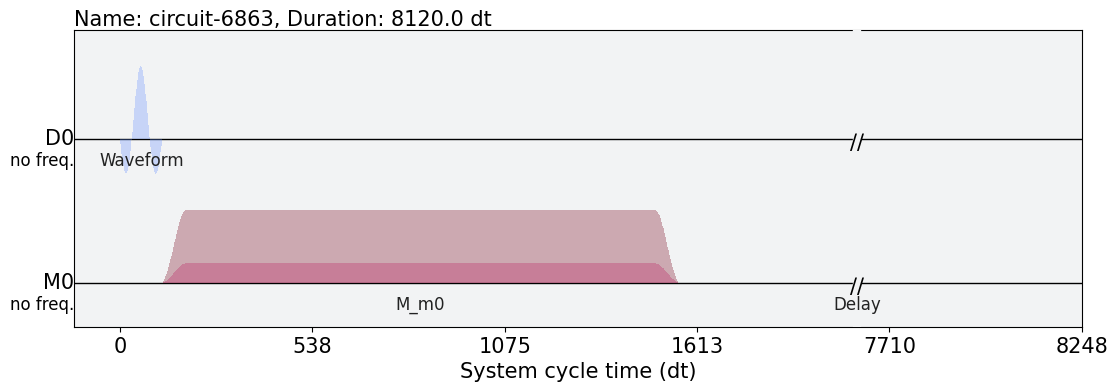

In [1036]:
rabi_schedule = qk.schedule(exp_rabi_circs[0], backend)
rabi_schedule.draw()

In [1037]:
num_shots_per_point = 1024
job = backend.run(exp_rabi_circs, shots=num_shots_per_point)
job.job_id()

'cqw9banae5gg008mfby0'

In [1055]:
provider.retrieve_job("cqw9banae5gg008mfby0").status()

<JobStatus.DONE: 'job has successfully run'>

### Job ids
First run:
- x1 pulse: "cqt73z7ch2mg008qv4f0" with ``drive_amps = np.linspace(0.5, 1.5, 50)``
- x2 pulse: "cqt74tb9nfw0008hrmkg" with ``drive_amps = np.linspace(0.5, 1.5, 50)``
- sx1 pulse: "cqt75349nfw0008hrmm0" with ``drive_amps = np.linspace(0.5, 1.5, 50)``
- sx2 pulse: "cqt75cx36d60008hyj90" with ``drive_amps = np.linspace(0.5, 1.5, 50)``

Second run:
- x1 pulse: "cqw9aj2b2cd0008vnvz0" with ``drive_amps = np.linspace(0.1, 1.2, 50)``
- x2 pulse: "cqw9azb7s450008tv4fg" with ``drive_amps = np.linspace(0.1, 1.2, 50)``
- sx1 pulse: "cqw9b4wae5gg008mfbwg" with ``drive_amps = np.linspace(0.1, 1.2, 50)``
- sx2 pulse: "cqw9banae5gg008mfby0" with ``drive_amps = np.linspace(0.1, 1.2, 50)``

## Retrieve jobs and fit data

### x1 

In [1042]:
result = provider.retrieve_job("cqw9aj2b2cd0008vnvz0").result()

In [1043]:
rabi_data = []
for i in range(len(drive_amps)):
    prob1 = result.get_counts(i)["1"] / num_shots_per_point
    rabi_data.append(prob1)

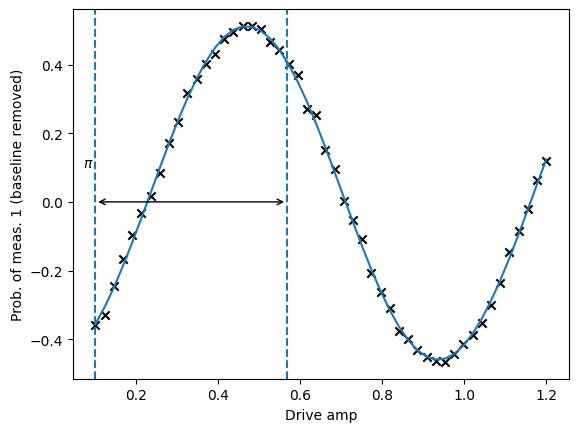

In [1044]:
rabi_values = []

for i in rabi_data:
    rabi_values.append(i)

rabi_values = np.real(baseline_remove(rabi_values))

fit_params, y_fit = fit_function(drive_amps,
                                 rabi_values, 
                                 lambda x, A, B, drive_period, phi: (A*np.cos(2*np.pi*x/drive_period - phi) + B),
                                 [1, 0.5, 1, 0.5])

plt.scatter(drive_amps, rabi_values, marker='x', color='black')
plt.plot(drive_amps, y_fit)

drive_period = fit_params[2] # get period of rabi oscillation

plt.axvline(drive_amps[0] + drive_period/2, linestyle='--')
plt.axvline(drive_amps[0], linestyle='--')
plt.annotate("", xy=(drive_amps[0], 0), xytext=(drive_amps[0] + drive_period/2,0), arrowprops=dict(arrowstyle="<->"))
plt.annotate("$\pi$", xy=(drive_amps[0]-0.03, 0.1))

plt.xlabel("Drive amp")
plt.ylabel("Prob. of meas. 1 (baseline removed)")
plt.show()

In [1045]:
# divided by 2 for x
drive_period / 2

0.46749867296152847

### x2

In [1046]:
result = provider.retrieve_job("cqw9azb7s450008tv4fg").result()

In [1047]:
rabi_data = []
for i in range(len(drive_amps)):
    prob1 = result.get_counts(i)["1"] / num_shots_per_point
    rabi_data.append(prob1)

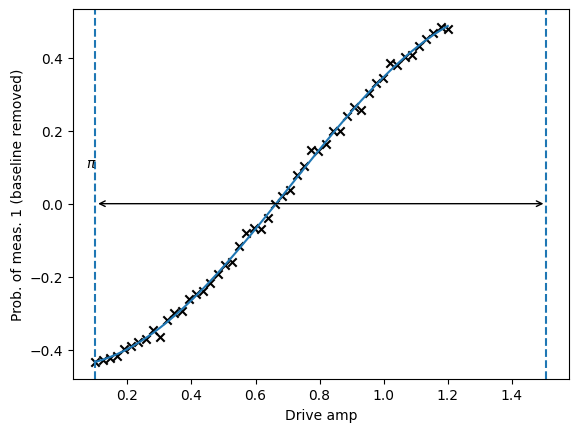

In [1048]:
rabi_values = []

for i in rabi_data:
    rabi_values.append(i)

rabi_values = np.real(baseline_remove(rabi_values))

fit_params, y_fit = fit_function(drive_amps,
                                 rabi_values, 
                                 lambda x, A, B, drive_period, phi: (A*np.cos(2*np.pi*x/drive_period - phi) + B),
                                 [1, 0.2, 1, 0.5])

plt.scatter(drive_amps, rabi_values, marker='x', color='black')
plt.plot(drive_amps, y_fit)

drive_period = fit_params[2] # get period of rabi oscillation

plt.axvline(drive_amps[0] + drive_period/2, linestyle='--')
plt.axvline(drive_amps[0], linestyle='--')
plt.annotate("", xy=(drive_amps[0], 0), xytext=(drive_amps[0] + drive_period/2,0), arrowprops=dict(arrowstyle="<->"))
plt.annotate("$\pi$", xy=(drive_amps[0]-0.03, 0.1))

plt.xlabel("Drive amp")
plt.ylabel("Prob. of meas. 1 (baseline removed)")
plt.show()

In [1049]:
# divided by 2 for x
drive_period / 2

1.4072037736010756

### sx1

In [1051]:
result = provider.retrieve_job("cqw9b4wae5gg008mfbwg").result()

In [1052]:
rabi_data = []
for i in range(len(drive_amps)):
    prob1 = result.get_counts(i)["1"] / num_shots_per_point
    rabi_data.append(prob1)

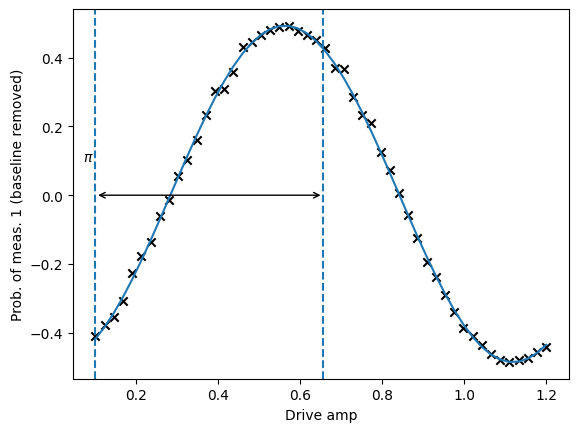

In [1053]:
rabi_values = []

for i in rabi_data:
    rabi_values.append(i)

rabi_values = np.real(baseline_remove(rabi_values))

fit_params, y_fit = fit_function(drive_amps,
                                 rabi_values, 
                                 lambda x, A, B, drive_period, phi: (A*np.cos(2*np.pi*x/drive_period - phi) + B),
                                 [1, 0.5, 1, 0.5])

plt.scatter(drive_amps, rabi_values, marker='x', color='black')
plt.plot(drive_amps, y_fit)

drive_period = fit_params[2] # get period of rabi oscillation

plt.axvline(drive_amps[0] + drive_period/2, linestyle='--')
plt.axvline(drive_amps[0], linestyle='--')
plt.annotate("", xy=(drive_amps[0], 0), xytext=(drive_amps[0] + drive_period/2,0), arrowprops=dict(arrowstyle="<->"))
plt.annotate("$\pi$", xy=(drive_amps[0]-0.03, 0.1))

plt.xlabel("Drive amp")
plt.ylabel("Prob. of meas. 1 (baseline removed)")
plt.show()

In [1054]:
# divided by 4 for sx
drive_period / 4

0.278161790575336

### sx2

In [1056]:
result = provider.retrieve_job("cqw9banae5gg008mfby0").result()

In [1057]:
rabi_data = []
for i in range(len(drive_amps)):
    prob1 = result.get_counts(i)["1"] / num_shots_per_point
    rabi_data.append(prob1)

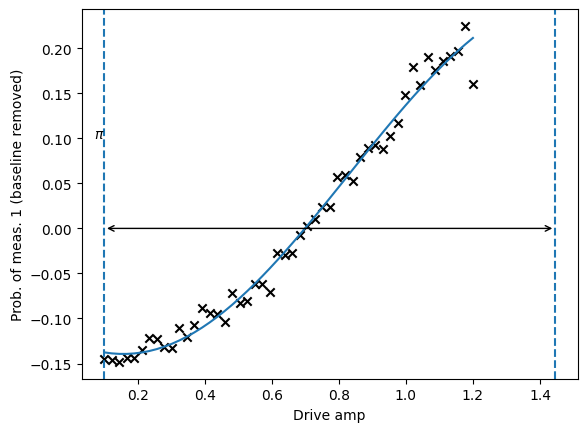

In [1062]:
rabi_values = []

for i in rabi_data:
    rabi_values.append(i)

rabi_values = np.real(baseline_remove(rabi_values))

fit_params, y_fit = fit_function(drive_amps,
                                 rabi_values, 
                                 lambda x, A, B, drive_period, phi: (A*np.cos(2*np.pi*x/drive_period - phi) + B),
                                 [1, 0.5, 1, 0.5])

plt.scatter(drive_amps, rabi_values, marker='x', color='black')
plt.plot(drive_amps, y_fit)

drive_period = fit_params[2] # get period of rabi oscillation

plt.axvline(drive_amps[0] + drive_period/2, linestyle='--')
plt.axvline(drive_amps[0], linestyle='--')
plt.annotate("", xy=(drive_amps[0], 0), xytext=(drive_amps[0] + drive_period/2,0), arrowprops=dict(arrowstyle="<->"))
plt.annotate("$\pi$", xy=(drive_amps[0]-0.03, 0.1))

plt.xlabel("Drive amp")
plt.ylabel("Prob. of meas. 1 (baseline removed)")
plt.show()

In [1060]:
# divided by 4 for sx
drive_period / 4

0.6725756269199937